# Attention backends

## Optimization ideas behind core attention backends

- **Common attention work**
    - Compute scores $QK^T$.
    - Apply a mask and softmax.
    - Multiply the weights by $V$.
    - An attention backend changes how these operations use compute units and memory. It does not change the model weights.
- **Eager**
    - Runs score calculation, softmax, and value mixing as separate operations
    - Reads and writes intermediate results between operations
    - Main bottleneck: memory traffic and separate kernel launches
    - Is useful as a reference
- **FlashAttention (v1)**
    - General idea: reduce memory transfers
    - Divide $Q$, $K$, and $V$ into blocks that fit in fast on-chip memory
    - Use an online softmax to combine blocks without storing the full attention matrix in GPU memory
    - Main gain: fewer reads and writes to GPU memory (especially for long prompt prefill)
- **FlashAttention-2**
    - General idea: use GPU cores more fully
    - Keep the block and online softmax idea from v1
    - Reduced work outside matrix multiplication
    - Split work across more GPU thread blocks
    - Divide work between warps so they exchange less data
    - Main gain: better parallel use of the GPU (especially when batch size or head count is small)
- **FlashAttention-3**
    - General idea: overlap work on newer GPUs
    - Keep the memory-saving method from earlier versions
    - On supported GPUs, overlap data movement, matrix multiplication, and softmax work
    - Use asynchronous hardware operations so compute units wait less often
    - Main gain: higher use of supported GPU hardware. The gain depends on the device and workload.
- **FlexAttention**
    - General idea: compile a custom attention rule
    - Express score changes and mask rules in Python
    - PyTorch compiles them into an attention kernel
    - Main gain: keep a fused kernel when an application needs a custom rule (such as sliding-window attention)


## Benchmark

In [9]:
import platform
import time

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-0.5B"
BACKENDS = [
    "eager",
    "sdpa",
    "kernels-community/flash-attn2",
    "flash_attention_2",
]
DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
DTYPE = (
    (
        torch.bfloat16 if torch.cuda.is_bf16_supported()
        else torch.float16
    ) if DEVICE == "cuda"
    else torch.float16 if DEVICE == "mps"
    else torch.float32
)
CONTEXT_LENGTHS = [128, 512, 1024]
REPEATS = 5

print(f"device={DEVICE}, dtype={DTYPE}, torch={torch.__version__}, transformers={transformers.__version__}")
print(torch.cuda.get_device_name() if DEVICE == "cuda" else platform.processor())

device=mps, dtype=torch.float16, torch=2.14.1, transformers=5.19.0
arm


## Load one model and make fixed prompts

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    attn_implementation="eager",
).to(DEVICE).eval()

seed_ids = tokenizer("Attention backends change how a transformer reads its context. ", add_special_tokens=False).input_ids
prompts = {
    length: torch.tensor((seed_ids * ((length // len(seed_ids)) + 1))[:length], device=DEVICE).unsqueeze(0)
    for length in CONTEXT_LENGTHS
}


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

## Time prefill stage

In [11]:
@torch.inference_mode()
def prefill_ms(input_ids):
    start = time.perf_counter()
    model(input_ids=input_ids, use_cache=True)
    return (time.perf_counter() - start) * 1000


rows = []
skipped = {}
for backend in BACKENDS:
    try:
        model.set_attn_implementation(backend)
        for length, input_ids in prompts.items():
            # prefill_ms(input_ids)  # warm-up; also compiles kernels when needed
            for trial in range(REPEATS):
                elapsed_ms = prefill_ms(input_ids)
                rows.append({"backend": backend, "context_tokens": length, "trial": trial, "decode_ms": elapsed_ms})
        print(f"{backend}: measured")
    except Exception as exc:
        skipped[backend] = f"{type(exc).__name__}: {str(exc).splitlines()[0]}"
        rows = [row for row in rows if row["backend"] != backend]
        print(f"{backend}: skipped ({skipped[backend]})")

results = pd.DataFrame(rows)

eager: measured
sdpa: measured
kernels-community/flash-attn2: skipped (KeyError: '`kernels-community/flash-attn2` is not a valid attention implementation registered in the `AttentionInterface`')
flash_attention_2: skipped (KeyError: '`kernels-community/flash-attn2` is not a valid attention implementation registered in the `AttentionInterface`')


## Compare measured time

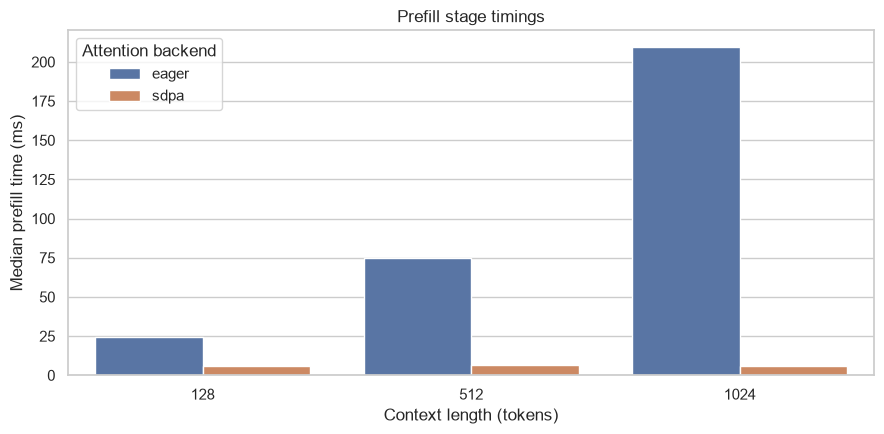

In [12]:
median_ms = (results.groupby(["backend", "context_tokens"], as_index=False)["decode_ms"].median())

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=median_ms, x="context_tokens", y="decode_ms", hue="backend",
    hue_order=[name for name in BACKENDS if name in set(median_ms["backend"])],
    ax=ax
)
ax.set(
    xlabel="Context length (tokens)", ylabel="Median prefill time (ms)",
    title="Prefill stage timings"
)
ax.legend(title="Attention backend")
plt.tight_layout()
plt.show()


## Sources

- [Hugging Face: attention backends](https://huggingface.co/docs/transformers/attention_interface)
- [PyTorch: scaled dot product attention](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html)
- [FlashAttention paper](https://arxiv.org/abs/2205.14135)
- [FlashAttention-2 paper](https://arxiv.org/abs/2307.08691)
- [FlashAttention-3 paper](https://arxiv.org/abs/2407.08608)
- [PyTorch: FlexAttention for inference](https://pytorch.org/blog/flexattention-for-inference/)
- [PyTorch: FlexAttention API](https://docs.pytorch.org/docs/stable/nn.attention.flex_attention.html)
- [Qwen2.5-0.5B model card](https://huggingface.co/Qwen/Qwen2.5-0.5B)
